## Problem Setting
We have an asset price $(S_t)_{t \ge 0}$ following the Black-Scholes SDE, $\frac{dS_t}{S_t} = \mu dt + \sigma dW_t$ with $(W_t)_t$ the standard brownian motion.

We can expressed the price $V = (F(t,S_t))_{t \in [0,T], S_t \in \mathbb{R}}$ of an option with payoff $h(S_T)$ as following:

\begin{equation} 
    {\partial_t F} + r S_t {\partial_x F} + \frac{\sigma^{2}}{2}{S_t}^2 {\partial_xx F} - rV = 0 
\end{equation}
With $r$ the risk free rate of growth.

In the case of the general form of a semilinear parabolic PDE
\begin{equation}
    \partial_t u + \mu(t,x) \nabla_x u + \frac{1}{2}Tr(\sigma(t,x)[\sigma(t,x)]^{*}Hess_x(u)) + f(t,x,u,[\sigma(t,x)]^{*}\nabla_x u) = 0
\end{equation}

Here we're working on the particular case where:
\begin{equation}
    \begin{cases}
        u = V \\
        \mu(t,x) = rx \\
        \sigma(t,x) = \sigma x \\
        f(t,x,u, [\sigma(t,x)]^{*}\nabla_x u) = -ru \\ 
    \end{cases} \\
    \text{with the terminal condition } u(T,x) = g(x) 
\end{equation}

*In the case of a call option we would have $g(x) = (x - K)_{+}$ with $K$ the strike price.*


...


The training loop will consist of :

1. Sampling Brownian Paths
2. Simulate $S_t$
3. Forward pass to get $Z_t$
4. Propagate $Y_t$
5. Compute $g(S_T)$ (payoff)
6. Compute terminal loss
7. Backpropagate
8. Update : 
\begin{equation}
    \begin{cases}
        \text{weights of the neural net} \\
        Y_0 \\
    \end{cases}
\end{equation}

In [1]:
#imports
import numpy as np
#import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import norm

#constants
T=1
mu = 0.05
sigma = 0.2
r= 0.02

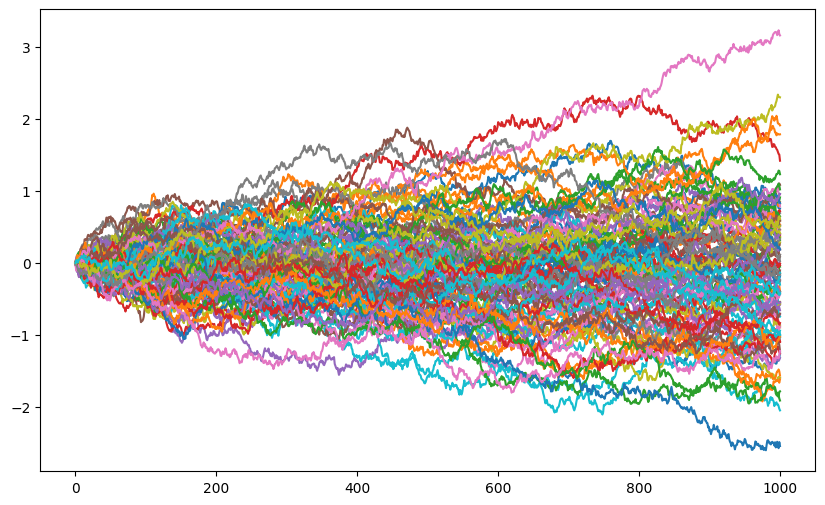

In [2]:
#we write a function to sample brownian paths
def brownian_paths(num_of_paths, size, T=T):
    dt = T/(size+1)
    Z = np.random.normal(0,np.sqrt(dt), (num_of_paths, size))
    W = np.concatenate([np.zeros((num_of_paths, 1)), np.cumsum(Z, axis=1)], axis=1)

    return W

plt.figure(figsize=(10,6))
paths = brownian_paths(1000, 1000, 1)
for i in range(100):
    plt.plot(paths[i])

In [5]:
brownian_paths(100, 1000, 1).shape

(100, 1001)

[[100.         101.60285788 103.91601022  99.90338443  92.30184043
   98.68006642  98.48736656 100.00579919  91.83605867  93.50249495
   86.03578458]
 [ 90.          98.54135951  93.17680262  88.94496912  93.21528209
   87.87933422  91.98959168  97.2573897   92.54023467  88.9034093
   89.95373205]]


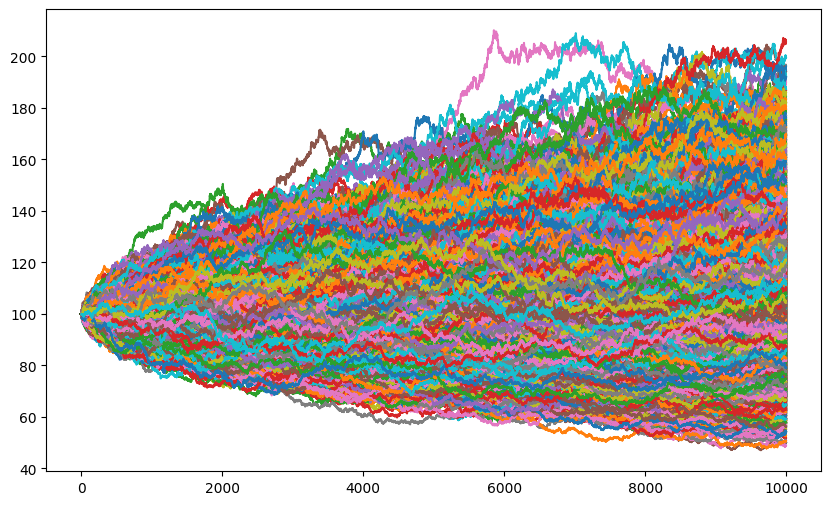

In [ ]:
def S_path(S0, W_path, r=r, sigma=sigma, T=T, chunk_size=None, full_path=True):
    if not isinstance(S0, (int, float)):
        assert len(S0) == W_path.shape[0], "S0 and W_path must have the same number of paths"
    num_paths, size = W_path.shape
    dt = T / size

    W_lagged = np.concatenate([np.zeros((num_paths, 1)), W_path[:, :-1]], axis=1, dtype=np.float32)
    dW = (W_path - W_lagged)[:, 1:]          

    S0 = np.broadcast_to(np.asarray(S0, dtype=np.float32), (num_paths,)).copy()

    if chunk_size is None:
        chunk_size = size - 1

    if full_path:
        S = np.empty((num_paths, size), dtype=np.float32)
        S[:, 0] = S0
        current = S0.copy()
        for start in range(0, size - 1, chunk_size):
            end = min(start + chunk_size, size - 1)
            dW_chunk = dW[:, start:end]                     
            growth_chunk = 1 + r * dt + sigma * dW_chunk
            cum_chunk = np.cumprod(growth_chunk, axis=1)
            S[:, start+1:end+1] = current[:, None] * cum_chunk
            current = S[:, end]                             
        return S, S[:, -1]
    else:
        S = S0.copy()
        for start in range(0, size - 1, chunk_size):
            end = min(start + chunk_size, size - 1)
            dW_chunk = dW[:, start:end]
            growth_chunk = 1 + r * dt + sigma * dW_chunk
            S *= np.prod(growth_chunk, axis=1)
        return S


print(S_path(brownian_paths(2, 10, 1), [100, 90], mu=0.05 , sigma=0.2, T=1))

n=10000
k=10000
plt.figure(figsize=(10,6))
S0 = [100]*n
paths = brownian_paths(n, k, 1)
S = S_path(paths, S0)
for i in range(n):
    plt.plot(S[i])

In [ ]:
def call_payoff(S, strikes):
    return np.maximum(S - strikes, 0)

def ana_call_price(St, K, time_to_maturity, mu=mu, sigma=sigma):
    d1 = (np.log(St/K)+ time_to_maturity*(r + (sigma**2)/2))/(sigma*np.sqrt(time_to_maturity))
    d2 = d1 - (sigma*np.sqrt(time_to_maturity))

    F = norm.cdf
    price = St*F(d1) - np.exp(-r*time_to_maturity)*K*F(d2)
    return price

ana_call_price(St=100, K=100, time_to_maturity=T, mu=mu, sigma=sigma)

np.float64(8.916037278572539)

In [ ]:
class BSDE_model(tf.keras.Model):
    def __init__(self, Y0, S0, T, N, sigma=sigma, option_payoff=call_payoff, r=0.05, strikes=[100], num_layers=3, units=10):
        super(BSDE_model, self).__init__()
        self.S0 = np.array(S0, dtype=np.float32)
        self.r = r  
        self.T = T
        self.sigma = sigma
        self.N = N
        self.h = T/N
        self.Y0 = tf.Variable(Y0, trainable=True, dtype=tf.float32)
        self.Y = [Y0]
        self.strikes = strikes
        self.option_payoff = option_payoff  
        self.training_dim = self.S0.shape[0] if isinstance(self.S0, (list, np.ndarray)) else 1

        layers = [tf.keras.layers.Dense(units, activation='relu') for _ in range(num_layers)]
        output_layer = tf.keras.layers.Dense(1, activation=None)

        self.hidden_layers = layers
        self.output_layer = output_layer

    def call(self, inputs):
        x = inputs
        for layer in self.hidden_layers:
            x = layer(x)
        output = self.output_layer(x)
        return output
    
    @tf.function
    def compute_Y_path(self):
        Y = self.Y0
        S = self.S0

        option_payoff = self.option_payoff
        W_paths = brownian_paths(self.training_dim, self.N, self.T)
        t = [i*self.h for i in range(self.N+1)]

        for i in range (1, self.N+1):
            tn = tf.fill([self.training_dim], t[i])
            S = S + self.r*S*self.h + self.sigma*S*(W_paths[:, i] - W_paths[:, i-1])
            xn = tf.stack([tn, S], axis=1)
            Zn = self.call(inputs=xn)
            Zn = tf.squeeze(Zn, axis=-1)
            Yn = Y + self.r*Y*self.h + Zn*(W_paths[:, i] - W_paths[:, i-1])
            Y = Yn

        payoff_loss = tf.keras.losses.MSE(option_payoff(S, self.strikes), Y)
        return Y, payoff_loss

    def train(self, epochs=10, learning_rate=0.001, 
                optimizer=tf.keras.optimizers.SGD,
                ):
        option_payoff=self.option_payoff
        optimizer = optimizer(learning_rate=learning_rate)
        for epoch in range(epochs):
            with tf.GradientTape() as tape:
                self.Y, loss = self.compute_Y_path()
            gradients = tape.gradient(loss, self.trainable_variables)
            optimizer.apply_gradients(zip(gradients, self.trainable_variables))
            if epoch % 10 == 0:
                print(f"Epoch {epoch}, Loss: {loss.numpy()}")        

SyntaxError: duplicate argument 'r' in function definition (2522803643.py, line 2)

In [241]:
BSDE_model_instance = BSDE_model(Y0=10, S0=[100]*512, r=r, T=T, N=1000, option_payoff=call_payoff, num_layers=3, units=12)
BSDE_model_instance.train(epochs=300, learning_rate=1e-3)

KeyboardInterrupt: 

In [230]:
print(ana_call_price(St=100, K=100, time_to_maturity=T, mu=mu, sigma=sigma))
print(BSDE_model_instance(tf.constant([[100., 0.]])))


8.916037278572539
tf.Tensor([[9.96338]], shape=(1, 1), dtype=float32)
